# RQ3：用 Conformal Prediction 为 72 小时漂流轨迹构造可靠的不确定性范围

**研究问题：**点预测只能告诉我们“模型认为 drifter 最可能在哪里”，但不能告诉我们这个预测有多可靠。
本 Notebook 在不重新调参、不接触 test set 的前提下，使用 RQ1 已训练完成的 FNN 作为固定点预测器，
再用独立的 calibration partition 把历史预测误差转换为可解释的预测区域。

本文件会依次回答：

1. conformal prediction 到底在做什么？
2. training、calibration、test 三个 partition 分别承担什么角色？
3. 如何从 calibration error 得到有限样本修正后的半径？
4. 80%、90%、95% 预测区域在 test set 上是否达到目标 coverage？
5. 区域越可靠是否一定越好？如何同时评价 coverage 和 sharpness？
6. 总体 coverage 足够时，Kuroshio Core 等不同 regime 内是否也可靠？
7. “每个时刻分别覆盖”与“整条 72 h 轨迹同时覆盖”有什么区别？

> 重要：Conformal prediction 不会让中心预测更准确。它把过去 calibration cases 上的误差校准成一个范围，
> 从而表达“真实位置有多大概率落在这个范围里”。

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("找不到 data/processed。请从项目目录或其子目录打开本 Notebook。")

PROCESSED = PROJECT_ROOT / "data" / "processed"
RQ1_OUTPUT = PROJECT_ROOT / "output" / "rq1" / "en"
RQ2_DATA = PROJECT_ROOT / "RQ2" / "data"
OUTPUT_DIR = PROJECT_ROOT / "output" / "rq3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
RANDOM_SEED = 3001
ALPHAS = [0.20, 0.10, 0.05]
MAIN_ALPHA = 0.10

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("项目目录：", PROJECT_ROOT)
print("RQ3 输出目录：", OUTPUT_DIR)

Matplotlib is building the font cache; this may take a moment.


项目目录： /Users/roger/Documents/data3001-project
RQ3 输出目录： /Users/roger/Documents/data3001-project/output/rq3


## 1. 先把三个数据 partition 的职责彻底分清楚

| Partition | Drifters / cases | 在 RQ3 中的作用 | 可以做什么 | 不可以做什么 |
|---|---:|---|---|---|
| Training | 364 assigned drifters / 3,591 cases | 拟合 FNN | 学习神经网络权重、选择结构与正则化 | 不能用于宣称最终 coverage |
| Calibration | 78 assigned drifters / 769 cases | 估计 conformal 半径 | 把模型误差校准成 80/90/95% 区域 | 不能再次训练或调 FNN |
| Test | 79 assigned drifters / 757 cases | 最终检验 | 只在所有方法固定后评价 coverage 与区域大小 | 不能看完结果后反复改半径再回来测试 |

这里的 assigned drifter 数是最初分区数；其中只有拥有完整 96 小时 forecast case 的 drifter 会贡献 cases。
分区是按完整 drifter ID 完成的，因此同一 drifter 的 cases 不会跨 partition，避免 drifter-level leakage。

In [2]:
origins = (
    pd.read_parquet(PROCESSED / "forecast_origins.parquet")
    .sort_values("forecast_case_id")
    .reset_index(drop=True)
)
split_summary = (
    origins.groupby("partition", sort=False)
    .agg(usable_drifters=("ID", "nunique"), forecast_cases=("forecast_case_id", "size"))
    .reindex(["training", "calibration", "test"])
)
split_summary.loc["Total"] = split_summary.sum()
display(split_summary)

assert split_summary.loc["training", "forecast_cases"] == 3591
assert split_summary.loc["calibration", "forecast_cases"] == 769
assert split_summary.loc["test", "forecast_cases"] == 757

,usable_drifters,forecast_cases
partition,,
training,311,3591
calibration,66,769
test,71,757
Total,448,5117


## 2. Conformal prediction 的核心思想

对 calibration case $i$、lead time $t$，先计算固定 FNN 点预测与真实位置之间的 Haversine separation error：

$$s_{i,t}=d_{\mathrm{Haversine}}(\widehat{\mathbf{x}}_{i,t},\mathbf{x}_{i,t}).$$

$s_{i,t}$ 就是 **nonconformity score（不符合度分数）**：

- 误差小：这个样本与模型的典型行为比较“符合”；
- 误差大：这个样本更“不符合”模型。

对目标 miscoverage $\alpha$，例如 $\alpha=0.10$，我们取 calibration scores 的有限样本修正分位数：

$$k=\left\lceil(n_{cal}+1)(1-\alpha)\right\rceil,\qquad
q_t=s_{(k),t}^{cal}.$$

然后以 FNN 预测位置为圆心、$q_t$ km 为半径构造预测区域：

$$C_t(X)=\{z:d_{\mathrm{Haversine}}(z,\widehat{x}_t)\le q_t\}.$$

如果新的 test case 与 calibration cases 近似 exchangeable，理论目标是：

$$P\{x_t\in C_t(X)\}\ge 1-\alpha.$$

**不要把 90% coverage 错读成：**“这个单独圆有 90% 的主观概率包含真值”。
更准确的频率学派解释是：对许多同分布的新 cases 重复使用该程序，长期至少约 90% 的圆会覆盖真值。

## 3. 重建 RQ1 的固定 FNN 输入与真实目标

每个 case 的 98 个输入为：

- forecast origin 的纬度、经度：2 个；
- 过去 24 小时每小时的相对东向位移、相对北向位移、东向速度、北向速度：$24\times4=96$ 个。

总计 $2+96=98$。FNN 输出未来 72 小时的东/北位移，共 $72\times2=144$ 个数。

In [3]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    return distance_km * np.sin(bearing), distance_km * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

In [4]:
observations = pd.read_parquet(
    PROCESSED / "region_A_observations.parquet",
    columns=["ID", "segment_id", "segment_step", "latitude", "longitude", "ve", "vn"],
)
n_cases = len(origins)

history = origins[[
    "forecast_case_id", "ID", "segment_id", "history_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history["history_index"] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history["segment_step"] = history["history_start_step"] + history["history_index"]
history = history.merge(
    observations, on=["ID", "segment_id", "segment_step"],
    how="left", validate="many_to_one",
).sort_values(["forecast_case_id", "history_index"]).reset_index(drop=True)

history["relative_east_km"], history["relative_north_km"] = latlon_to_local_km(
    history["origin_latitude"], history["origin_longitude"],
    history["latitude"], history["longitude"],
)
history_values = history[[
    "relative_east_km", "relative_north_km", "ve", "vn",
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)

X = np.column_stack([
    origins["origin_latitude"].to_numpy(),
    origins["origin_longitude"].to_numpy(),
    history_values.reshape(n_cases, -1),
]).astype(float)

targets = origins[[
    "forecast_case_id", "ID", "segment_id", "target_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets["lead_time_hours"] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets["segment_step"] = targets["target_start_step"] + targets["lead_time_hours"] - 1
targets = targets.merge(
    observations[["ID", "segment_id", "segment_step", "latitude", "longitude"]],
    on=["ID", "segment_id", "segment_step"], how="left", validate="many_to_one",
).sort_values(["forecast_case_id", "lead_time_hours"]).reset_index(drop=True)

checks = pd.Series({
    "cases = 5,117": n_cases == 5117,
    "X shape = 5,117 × 98": X.shape == (5117, 98),
    "每个 case 有 72 个真实未来位置": targets.groupby("forecast_case_id").size().eq(72).all(),
    "X 无缺失或无穷值": np.isfinite(X).all(),
}, name="通过")
display(checks.to_frame())
assert checks.all()

,通过
"cases = 5,117",True
"X shape = 5,117 × 98",True
每个 case 有 72 个真实未来位置,True
X 无缺失或无穷值,True


## 4. 载入已经固定的 FNN，而不是使用 calibration/test 重新训练

这里载入的是 RQ1 用 training partition 拟合完成的 98 → 128 → 64 → 144 网络。
calibration 与 test 均只经过 forward pass，不参与反向传播。

In [5]:
archive = np.load(RQ1_OUTPUT / "fnn_model_parameters.npz")

def predict_saved_fnn(X_new):
    z = (X_new - archive["x_mean"]) / archive["x_scale"]
    z = np.maximum(z @ archive["W1"] + archive["b1"], 0.0)
    z = np.maximum(z @ archive["W2"] + archive["b2"], 0.0)
    y_standard = z @ archive["W3"] + archive["b3"]
    return y_standard * archive["y_scale"] + archive["y_mean"]

predicted_local = predict_saved_fnn(X).reshape(n_cases, HORIZON_HOURS, 2)

origin_lat_2d = np.repeat(origins["origin_latitude"].to_numpy()[:, None], HORIZON_HOURS, axis=1)
origin_lon_2d = np.repeat(origins["origin_longitude"].to_numpy()[:, None], HORIZON_HOURS, axis=1)
pred_lat, pred_lon = local_km_to_latlon(
    origin_lat_2d, origin_lon_2d,
    predicted_local[:, :, 0], predicted_local[:, :, 1],
)
true_lat = targets["latitude"].to_numpy().reshape(n_cases, HORIZON_HOURS)
true_lon = targets["longitude"].to_numpy().reshape(n_cases, HORIZON_HOURS)
errors_km = haversine_km(pred_lat, pred_lon, true_lat, true_lon)

cal_idx = np.flatnonzero(origins["partition"].eq("calibration").to_numpy())
test_idx = np.flatnonzero(origins["partition"].eq("test").to_numpy())

# 验证这里复现了 RQ1 已保存的 test 结果。
saved_test = pd.read_csv(RQ1_OUTPUT / "fnn_test_case_metrics.csv")
max_difference = np.max(np.abs(errors_km[test_idx, -1] - saved_test["final_72h_error_km"]))
print(f"与 RQ1 已保存 72 h test error 的最大差异：{max_difference:.3e} km")
assert max_difference < 1e-8

与 RQ1 已保存 72 h test error 的最大差异：1.421e-14 km


## 5. 有限样本 conformal quantile：为什么不能直接调用普通 90th percentile？

普通经验 90% 分位数可能在有限样本下略微偏小。Split conformal 使用排序位置
$\lceil(n+1)(1-\alpha)\rceil$，相当于把分位数稍微向上修正。
对本项目 $n_{cal}=769$、$\alpha=0.1$：

$$k=\lceil770\times0.9\rceil=693.$$

所以取第 693 小的 calibration error。这个小小的“+1 修正”是有限样本 coverage 保证的一部分。

In [6]:
def conformal_quantile(scores, alpha):
    scores = np.asarray(scores, dtype=float)
    n = len(scores)
    k = min(n, int(np.ceil((n + 1) * (1 - alpha))))
    return np.partition(scores, k - 1)[k - 1]


quantile_rows = []
for alpha in ALPHAS:
    for lead_index in range(HORIZON_HOURS):
        q = conformal_quantile(errors_km[cal_idx, lead_index], alpha)
        quantile_rows.append({
            "alpha": alpha,
            "nominal_coverage": 1 - alpha,
            "lead_time_hours": lead_index + 1,
            "radius_km": q,
        })
quantiles = pd.DataFrame(quantile_rows)

display(
    quantiles[quantiles["lead_time_hours"].isin([24, 48, 72])]
    .pivot(index="lead_time_hours", columns="nominal_coverage", values="radius_km")
    .round(2)
)

nominal_coverage,0.80,0.90,0.95
lead_time_hours,,,
24,21.74,27.7,33.35
48,51.03,67.3,77.50
72,82.29,105.2,128.91


## 6. 在从未用于 calibration 的 test partition 上评价 coverage

对每个 test case 和 lead time，检查 Haversine error 是否不超过对应 conformal radius。

需要同时看两个互相制衡的指标：

- **Validity / coverage：**真实位置落入区域的比例，应该接近或高于 nominal coverage；
- **Efficiency / sharpness：**区域应该尽量小。一个覆盖整个海洋的圆 coverage 很高，但没有决策价值。

对半径 $q_t$ 的小圆，平面近似面积为 $\pi q_t^2$；精确球冠面积为
$2\pi R^2[1-\cos(q_t/R)]$。在本项目尺度下两者非常接近，这里报告精确球冠面积。

In [7]:
evaluation_rows = []
for alpha in ALPHAS:
    q = (
        quantiles.loc[quantiles["alpha"].eq(alpha)]
        .sort_values("lead_time_hours")["radius_km"].to_numpy()
    )
    covered = errors_km[test_idx] <= q[None, :]
    area = 2 * np.pi * EARTH_RADIUS_KM**2 * (1 - np.cos(q / EARTH_RADIUS_KM))
    for lead_index in range(HORIZON_HOURS):
        evaluation_rows.append({
            "alpha": alpha,
            "nominal_coverage": 1 - alpha,
            "lead_time_hours": lead_index + 1,
            "empirical_coverage": covered[:, lead_index].mean(),
            "radius_km": q[lead_index],
            "area_km2": area[lead_index],
            "n_test_cases": len(test_idx),
        })
coverage_by_lead = pd.DataFrame(evaluation_rows)

key_hours = coverage_by_lead[coverage_by_lead["lead_time_hours"].isin([24, 48, 72])].copy()
key_hours["nominal_coverage"] = key_hours["nominal_coverage"].map(lambda x: f"{x:.0%}")
display(key_hours[[
    "nominal_coverage", "lead_time_hours", "empirical_coverage", "radius_km", "area_km2",
]].round({"empirical_coverage": 3, "radius_km": 2, "area_km2": 0}))

,nominal_coverage,lead_time_hours,empirical_coverage,radius_km,area_km2
23,80%,24,0.812,21.74,1485.0
47,80%,48,0.832,51.03,8180.0
71,80%,72,0.839,82.29,21273.0
95,90%,24,0.890,27.70,2410.0
119,90%,48,0.918,67.30,14231.0
143,90%,72,0.918,105.20,34765.0
167,95%,24,0.938,33.35,3494.0
191,95%,48,0.943,77.50,18868.0
215,95%,72,0.958,128.91,52202.0


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


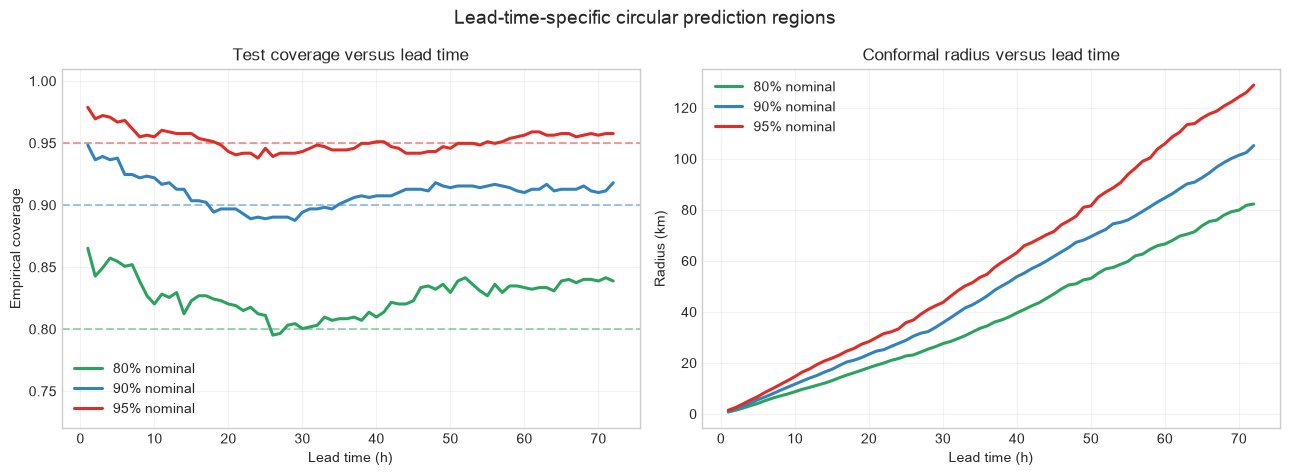

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = {0.8: "#2ca25f", 0.9: "#3182bd", 0.95: "#de2d26"}
for nominal, group in coverage_by_lead.groupby("nominal_coverage"):
    label = f"{nominal:.0%} nominal"
    axes[0].plot(group["lead_time_hours"], group["empirical_coverage"],
                 lw=2.2, color=colors[nominal], label=label)
    axes[0].axhline(nominal, color=colors[nominal], ls="--", alpha=0.45)
    axes[1].plot(group["lead_time_hours"], group["radius_km"],
                 lw=2.2, color=colors[nominal], label=label)

axes[0].set(title="Test coverage versus lead time", xlabel="Lead time (h)", ylabel="Empirical coverage", ylim=(0.72, 1.01))
axes[1].set(title="Conformal radius versus lead time", xlabel="Lead time (h)", ylabel="Radius (km)")
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
fig.suptitle("Lead-time-specific circular prediction regions", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rq3_coverage_and_radius_by_lead.png", dpi=200, bbox_inches="tight")
plt.show()

### 如何阅读上图？

- 半径随 lead time 增长，是因为长时距的点预测误差更大；这不是 conformal 造成误差，而是 conformal 忠实反映了 RQ1 的误差增长。
- 90% 区域在 24、48、72 h 的半径约为 27.70、67.30、105.20 km。
- 对应 test coverage 约为 89.0%、91.8%、91.8%。这说明总体 calibration 在 test set 上工作合理。
- 95% 区域更可靠，但面积增长很快。这就是 coverage 与 sharpness 的取舍。

## 7. Test drifter cluster bootstrap：coverage 估计本身也有不确定性

757 个 test cases 并不完全独立：同一个 drifter 可以产生多个 cases。
因此不能简单把 757 当成 757 个完全独立样本来计算很窄的置信区间。
这里以 **drifter 为单位**重采样：每次抽取 test drifters，再带上该 drifter 的全部 cases。
这样得到的 bootstrap interval 更尊重数据层级结构。

In [9]:
main_q = (
    quantiles.loc[quantiles["alpha"].eq(MAIN_ALPHA)]
    .sort_values("lead_time_hours")["radius_km"].to_numpy()
)
main_covered = errors_km[test_idx] <= main_q[None, :]
test_meta = origins.loc[test_idx, ["forecast_case_id", "ID"]].reset_index(drop=True)
test_drifters = test_meta["ID"].unique()
case_rows_by_drifter = {
    drifter: np.flatnonzero(test_meta["ID"].eq(drifter).to_numpy())
    for drifter in test_drifters
}

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_hours = [24, 48, 72]
bootstrap_values = {hour: [] for hour in bootstrap_hours}
for _ in range(2000):
    sampled_drifters = rng.choice(test_drifters, size=len(test_drifters), replace=True)
    sampled_rows = np.concatenate([case_rows_by_drifter[d] for d in sampled_drifters])
    for hour in bootstrap_hours:
        bootstrap_values[hour].append(main_covered[sampled_rows, hour - 1].mean())

bootstrap_summary = pd.DataFrame([
    {
        "lead_time_hours": hour,
        "coverage": main_covered[:, hour - 1].mean(),
        "cluster_bootstrap_lower_95": np.quantile(values, 0.025),
        "cluster_bootstrap_upper_95": np.quantile(values, 0.975),
        "test_drifters": len(test_drifters),
        "test_cases": len(test_idx),
    }
    for hour, values in bootstrap_values.items()
])
display(bootstrap_summary.round(3))

,lead_time_hours,coverage,cluster_bootstrap_lower_95,cluster_bootstrap_upper_95,test_drifters,test_cases
0,24,0.890,0.859,0.915,71,757
1,48,0.918,0.895,0.937,71,757
2,72,0.918,0.895,0.939,71,757


## 8. RQ2 × RQ3：总体 90% coverage 是否掩盖了 regime 间的不可靠性？

标准 split conformal 提供的是 **marginal coverage**：把所有同分布 test cases 混在一起时覆盖率足够。
它不会自动保证每个 ocean regime 都有 90% coverage。

这一步不重新调整半径，只把同一个全局 90% 区域分别放到 Shelf、Kuroshio Core、Transition、
Other Offshore 的 test cases 上检查。因此这是最直接的公平诊断。

In [10]:
regimes = pd.read_csv(RQ2_DATA / "forecast_case_regimes.csv")[["forecast_case_id", "regime"]]
test_regime_meta = (
    origins.loc[test_idx, ["forecast_case_id", "ID"]]
    .reset_index(drop=True)
    .merge(regimes, on="forecast_case_id", how="left", validate="one_to_one")
)
assert test_regime_meta["regime"].notna().all()

regime_rows = []
for regime, row_index in test_regime_meta.groupby("regime", sort=False).groups.items():
    row_index = np.asarray(list(row_index), dtype=int)
    for hour in [24, 48, 72]:
        regime_rows.append({
            "regime": regime,
            "lead_time_hours": hour,
            "n_cases": len(row_index),
            "n_drifters": test_regime_meta.loc[row_index, "ID"].nunique(),
            "empirical_coverage": main_covered[row_index, hour - 1].mean(),
            "global_radius_km": main_q[hour - 1],
            "median_error_km": np.median(errors_km[test_idx[row_index], hour - 1]),
            "rmse_km": np.sqrt(np.mean(errors_km[test_idx[row_index], hour - 1] ** 2)),
        })
regime_coverage = pd.DataFrame(regime_rows)
display(regime_coverage.round(3))

,regime,lead_time_hours,n_cases,n_drifters,empirical_coverage,global_radius_km,median_error_km,rmse_km
0,Shelf,24,112,28,0.955,27.696,8.294,12.840
1,Shelf,48,112,28,0.973,67.304,17.419,28.087
2,Shelf,72,112,28,0.964,105.196,25.693,41.614
3,Other Offshore,24,341,41,0.959,27.696,10.030,14.272
4,Other Offshore,48,341,41,0.971,67.304,24.098,32.578
5,Other Offshore,72,341,41,0.965,105.196,40.603,52.602
6,Transition,24,165,43,0.855,27.696,12.172,18.906
7,Transition,48,165,43,0.903,67.304,27.678,42.951
8,Transition,72,165,43,0.897,105.196,41.080,66.189
9,Kuroshio Core,24,139,45,0.712,27.696,20.528,27.167


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


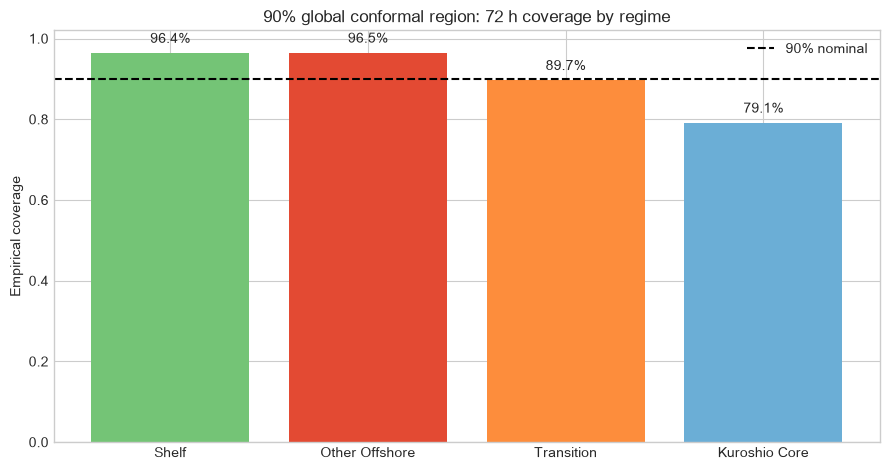

In [11]:
plot_data = regime_coverage[regime_coverage["lead_time_hours"].eq(72)].copy()
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(plot_data["regime"], plot_data["empirical_coverage"], color=["#74c476", "#e34a33", "#fd8d3c", "#6baed6"])
ax.axhline(0.90, color="black", ls="--", lw=1.5, label="90% nominal")
ax.set(title="90% global conformal region: 72 h coverage by regime", ylabel="Empirical coverage", ylim=(0, 1.02))
ax.legend(frameon=False)
for bar, value in zip(bars, plot_data["empirical_coverage"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.025, f"{value:.1%}", ha="center", fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rq3_72h_coverage_by_regime.png", dpi=200, bbox_inches="tight")
plt.show()

### 这里是 RQ3 最重要的科学发现之一

全体 test cases 的 72 h coverage 约为 91.8%，看起来达到了 90% 目标；
但 Kuroshio Core 内的 coverage 只有约 79.1%，明显偏低。
Shelf 与 Other Offshore 则超过 96%，说明同一个全局半径在这些区域相对保守。

这与 RQ2 完全一致：Kuroshio Core 的流速更高、动力变化更强，FNN 误差分布更宽。
因而“总体有效”不等于“每个海洋环境内都同样可靠”。

可考虑的下一步包括：

1. **Mondrian / group-conditional conformal：**每个 regime 使用自己的 calibration scores；
2. **Locally adaptive conformal：**先预测每个 case 的难度，再对标准化误差做 conformal calibration；
3. **加入环境变量：**将 GLORYS current、bathymetry、season 等输入误差尺度模型；
4. **谨慎处理小样本：**分组越细，每组 calibration cases 越少，分位数越不稳定，区域也可能变大。

这些方法应该在 calibration partition 内预先定义，再对 test 只评价一次。

## 9. Pointwise coverage 与 simultaneous trajectory coverage 不一样

前面的 90% 圆表示：在某个固定 lead time $t$，约 90% 的真实位置被覆盖。
它**不表示**一条轨迹的 72 个时刻会同时有 90% 概率全部被覆盖。
72 次覆盖事件累积后，至少一个时刻越界并不罕见。

若希望整条轨迹同时被覆盖，可先用 calibration median error $m_t$ 表示每个 lead time 的典型尺度，
然后对每个 calibration case 定义：

$$S_i=\max_{t=1,\ldots,72}\frac{e_{i,t}}{m_t}.$$

再对 $S_i$ 做一次 90% conformal quantile。最终半径为 $q^{sim}m_t$。
这样评价的是“72 个时刻全部在 band 内”的 case-level simultaneous coverage。

In [12]:
lead_scale = np.maximum(np.median(errors_km[cal_idx], axis=0), 1e-6)
simultaneous_scores = np.max(errors_km[cal_idx] / lead_scale[None, :], axis=1)
simultaneous_multiplier = conformal_quantile(simultaneous_scores, MAIN_ALPHA)
simultaneous_radius = simultaneous_multiplier * lead_scale
simultaneously_covered = np.all(errors_km[test_idx] <= simultaneous_radius[None, :], axis=1)

pointwise_all_hours = np.all(main_covered, axis=1)
simultaneous_summary = pd.DataFrame({
    "method": ["逐时 90% 半径，但要求 72 点全部覆盖", "专门校准的 90% simultaneous band"],
    "whole_trajectory_coverage": [pointwise_all_hours.mean(), simultaneously_covered.mean()],
    "radius_24h_km": [main_q[23], simultaneous_radius[23]],
    "radius_48h_km": [main_q[47], simultaneous_radius[47]],
    "radius_72h_km": [main_q[71], simultaneous_radius[71]],
})
display(simultaneous_summary.round(3))

,method,whole_trajectory_coverage,radius_24h_km,radius_48h_km,radius_72h_km
0,逐时 90% 半径，但要求 72 点全部覆盖,0.741,27.696,67.304,105.196
1,专门校准的 90% simultaneous band,0.934,47.476,103.782,166.751


结果会显示：把 72 个“逐时 90% 圆”串起来后，整条轨迹全部落在里面的比例远低于 90%。
专门校准的 simultaneous band 可以恢复约 90% 的整轨迹 coverage，但半径显著更大。

所以应用时必须先问清楚：

- 搜救人员关心的是某个指定时刻的搜索区域？使用 pointwise region；
- 还是希望整个 72 h 期间都不漏掉目标？使用 simultaneous band。

## 10. 画一个具体 case：点预测、真实位置与 90% 圆

为避免只展示“最好看的”案例，这里自动选择 72 h error 最接近 test median 的 case。
圆在经纬度图上用局部近似绘制，仅用于视觉解释；coverage 计算始终使用 Haversine distance。

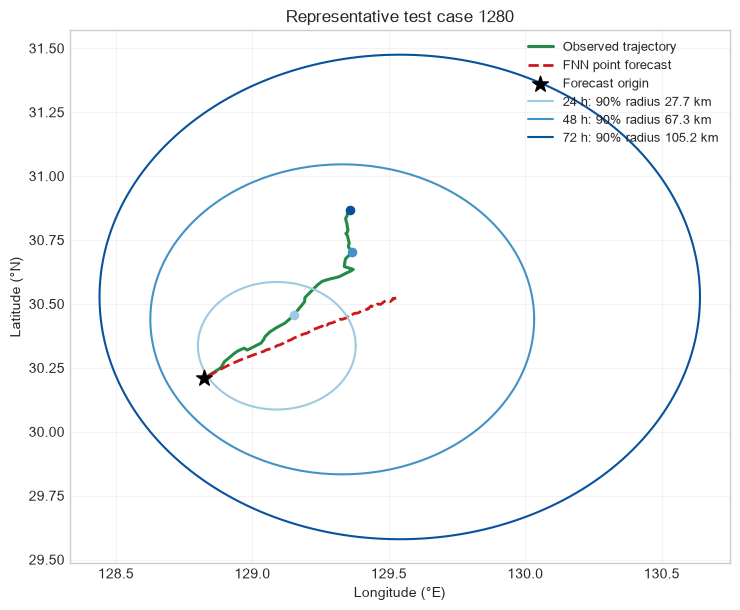

In [13]:
test_errors_72 = errors_km[test_idx, 71]
representative_row = np.argmin(np.abs(test_errors_72 - np.median(test_errors_72)))
case_index = test_idx[representative_row]
case_id = int(origins.loc[case_index, "forecast_case_id"])

fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.plot(true_lon[case_index], true_lat[case_index], color="#238b45", lw=2.2, label="Observed trajectory")
ax.plot(pred_lon[case_index], pred_lat[case_index], color="#cb181d", lw=2.0, ls="--", label="FNN point forecast")
ax.scatter(origins.loc[case_index, "origin_longitude"], origins.loc[case_index, "origin_latitude"],
           marker="*", s=140, color="black", zorder=5, label="Forecast origin")

for hour, color in [(24, "#9ecae1"), (48, "#4292c6"), (72, "#08519c")]:
    j = hour - 1
    theta = np.linspace(0, 2*np.pi, 240)
    radius = main_q[j]
    lat_center = pred_lat[case_index, j]
    lon_center = pred_lon[case_index, j]
    circle_lat = lat_center + (radius / 111.0) * np.sin(theta)
    circle_lon = lon_center + (radius / (111.0 * np.cos(np.deg2rad(lat_center)))) * np.cos(theta)
    ax.plot(circle_lon, circle_lat, color=color, lw=1.5, label=f"{hour} h: 90% radius {radius:.1f} km")
    ax.scatter(true_lon[case_index, j], true_lat[case_index, j], s=35, color=color, zorder=5)

ax.set(
    title=f"Representative test case {case_id}",
    xlabel="Longitude (°E)", ylabel="Latitude (°N)",
)
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rq3_representative_case_regions.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. 方法假设与限制：报告时必须主动说明

### 11.1 Exchangeability 不是“海洋必须静止不变”

Split conformal 的核心条件是 calibration 与未来 test cases 在统计上可交换。
本项目通过按 drifter 分区避免了同一 drifter 同时出现在 calibration/test，但仍可能有：

- 时间分布变化（1994–2022 中不同时期海洋状态不同）；
- 空间/regime 比例变化；
- 同一 drifter 内多个 cases 的相关性；
- 极端天气或未来气候条件与历史数据不同。

因此这里的 coverage 是对“与 calibration/test 类似的 Region A GDP drifter cases”的经验可靠性，
不是对任何时间、全球任何海域、任何漂浮物体的无条件保证。

### 11.2 Case-level calibration 与 drifter 内相关性

主分析把 769 个 calibration cases 当成分数。由于同一 calibration drifter 可能贡献多个 cases，
严格的独立同分布解释会被削弱。更保守的扩展可以每个 calibration drifter 聚合成一个 score，
或进行 hierarchical/cluster-aware conformal；代价是有效校准样本从 769 降到 66 个 usable drifters，
分位数更粗、区域可能更宽。

### 11.3 圆形区域不表达方向性

当前区域只有半径，不区分沿流向与横流向误差。Kuroshio 中误差很可能是方向性的。
后续可在局部 east/north 坐标中用 Mahalanobis score 或 conformal ellipse 构造椭圆区域。
但形状/协方差估计必须仅使用 training/calibration 数据。

### 11.4 Coverage 不是 accuracy

更大的区域能提高 coverage，却不能说明中心预测更准。报告必须同时给：

- 点预测 accuracy：median error、RMSE、ITE（RQ1/RQ2）；
- uncertainty validity：coverage（RQ3）；
- uncertainty efficiency：半径或面积（RQ3）。

## 12. 自动生成可用于报告的结果摘要

In [14]:
main_key = coverage_by_lead[
    coverage_by_lead["alpha"].eq(MAIN_ALPHA)
    & coverage_by_lead["lead_time_hours"].isin([24, 48, 72])
].copy()

summary_lines = [
    "### RQ3 结果摘要",
    "",
    "使用 769 个独立保留的 calibration cases 对 training-only FNN 进行 split conformal calibration。",
]
for row in main_key.itertuples():
    summary_lines.append(
        f"- {row.lead_time_hours} h：90% 半径 {row.radius_km:.2f} km；"
        f"757 个 held-out test cases 上 empirical coverage 为 {row.empirical_coverage:.1%}。"
    )
kuro_72 = regime_coverage.query("regime == 'Kuroshio Core' and lead_time_hours == 72").iloc[0]
summary_lines.extend([
    f"- 72 h 全体 test coverage 达标，但 Kuroshio Core 内只有 {kuro_72.empirical_coverage:.1%}，说明 marginal validity 掩盖了 regime-specific undercoverage。",
    f"- 专门校准的 simultaneous trajectory band 在 test set 上覆盖整条 72 h 轨迹的比例为 {simultaneously_covered.mean():.1%}。",
    "- 结论：split conformal 能把 FNN 点预测转换为总体上可靠的区域，但若要在不同海洋动力环境中均保持可靠，需要 regime-aware 或 locally adaptive calibration。",
])
display(Markdown("\n".join(summary_lines)))

### RQ3 结果摘要

使用 769 个独立保留的 calibration cases 对 training-only FNN 进行 split conformal calibration。
- 24 h：90% 半径 27.70 km；757 个 held-out test cases 上 empirical coverage 为 89.0%。
- 48 h：90% 半径 67.30 km；757 个 held-out test cases 上 empirical coverage 为 91.8%。
- 72 h：90% 半径 105.20 km；757 个 held-out test cases 上 empirical coverage 为 91.8%。
- 72 h 全体 test coverage 达标，但 Kuroshio Core 内只有 79.1%，说明 marginal validity 掩盖了 regime-specific undercoverage。
- 专门校准的 simultaneous trajectory band 在 test set 上覆盖整条 72 h 轨迹的比例为 93.4%。
- 结论：split conformal 能把 FNN 点预测转换为总体上可靠的区域，但若要在不同海洋动力环境中均保持可靠，需要 regime-aware 或 locally adaptive calibration。

## 13. 保存全部结果，方便海报和最终报告直接调用

In [15]:
quantiles.to_csv(OUTPUT_DIR / "rq3_conformal_quantiles.csv", index=False)
coverage_by_lead.to_csv(OUTPUT_DIR / "rq3_coverage_by_lead.csv", index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / "rq3_cluster_bootstrap_coverage.csv", index=False)
regime_coverage.to_csv(OUTPUT_DIR / "rq3_coverage_by_regime.csv", index=False)
simultaneous_summary.to_csv(OUTPUT_DIR / "rq3_simultaneous_trajectory_summary.csv", index=False)

saved = sorted(p.name for p in OUTPUT_DIR.iterdir())
print("已保存：")
for name in saved:
    print(" -", name)

已保存：
 - rq3_72h_coverage_by_regime.png
 - rq3_cluster_bootstrap_coverage.csv
 - rq3_conformal_quantiles.csv
 - rq3_coverage_and_radius_by_lead.png
 - rq3_coverage_by_lead.csv
 - rq3_coverage_by_regime.csv
 - rq3_representative_case_regions.png
 - rq3_simultaneous_trajectory_summary.csv


## 14. 最终可直接用于论文 Methods / Results 的英文表述

**Methods**  
We applied split conformal prediction to the fixed FNN trajectory forecasts. The FNN was fitted using
training drifters only. For each lead time, Haversine separation errors from 769 held-out calibration cases
were used as nonconformity scores. A finite-sample corrected empirical quantile defined a circular prediction
region centred on each FNN point forecast. Empirical coverage and region size were evaluated once on 757
held-out test cases. Coverage was additionally stratified by ocean regime, and uncertainty in the reported
coverage was assessed by resampling complete test drifters.

**Results**  
The lead-time-specific conformal regions achieved approximately nominal marginal coverage on the full test
set, while their radii increased with forecast horizon. However, regime-stratified evaluation revealed
undercoverage in the Kuroshio Core and conservative coverage in lower-error regimes. Thus, global split
conformal calibration provided useful overall uncertainty quantification but did not guarantee equal
reliability across heterogeneous ocean environments.

**一句话版本：**  
Overall conformal coverage was reliable, but uncertainty was not equally calibrated across ocean regimes,
with the strongest undercoverage occurring in the dynamically energetic Kuroshio Core.